<a href="https://colab.research.google.com/github/JiayuZzzzz/Machine-Learning_Regression-Model/blob/main/mnist.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## MNIST Classification


- How much can we improve MNIST classification performance, starting from the most simple approach to using modern methods?
- similar to  [this blog by Anderj Karpathy](https://karpathy.github.io/2022/03/14/lecun1989/)

In [ ]:
# download util functions
!wget https://gist.githubusercontent.com/p16i/6840926229e88f1713757689e8f49993/raw/f0b9c701b1c25848da202038de0a6b6e195403ce/utils.py

--2026-11-23 19:30:37--  https://gist.githubusercontent.com/p16i/6840926229e88f1713757689e8f49993/raw/f0b9c701b1c25848da202038de0a6b6e195403ce/utils.py
Resolving gist.githubusercontent.com (gist.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to gist.githubusercontent.com (gist.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1980 (1.9K) [text/plain]
Saving to: ‘utils.py.6’

utils.py.6          100%[===================>]   1.93K  --.-KB/s    in 0s      

2026-11-23 19:30:37 (79.1 MB/s) - ‘utils.py.6’ saved [1980/1980]



In [1]:
import torch
from torch.utils.data import random_split
from torchvision import datasets, transforms

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

train_data  = datasets.MNIST('../data', train=True, download=True, transform=transform)
test_data   = datasets.MNIST('../data', train=False, download=True, transform=transform)
train_data, val_data = random_split(train_data,[55000, 5000], generator = torch.Generator().manual_seed(42))

len(train_data), len(val_data), len(test_data)

Successfully renamed PrivateUse1 backend to 'tpu'. Device: device(type='tpu')
Registered Python module for 'tpu'.
Device type: tpu, Device index: default
Initializing TPU distributed runtime
100%|██████████| 9.91M/9.91M [00:00<00:00, 20.3MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 491kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.61MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 11.1MB/s]


(55000, 5000, 10000)

In [ ]:
torch.manual_seed(1)

In [ ]:
device = torch.accelerator.current_accelerator()
device

epochs = 5

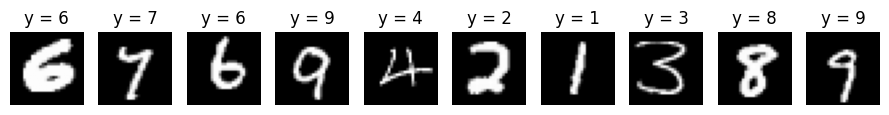

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 10, figsize=(9, 3))

for i in range(10):
    image, label = train_data[i]

    # undo normalization for display
    image = image * 0.3081 + 0.1307

    axes[i].imshow(image.squeeze(), cmap='gray')
    axes[i].set_title(f"y = {label}")
    axes[i].axis('off')

plt.tight_layout()
plt.show()

---
### MLP with Regression Loss

In [ ]:
from utils import train, evaluate

train_accuracies = {}
val_accuracies = {}

In [ ]:
import torch.nn as nn

class MLP(nn.Module):
    def __init__(self, input_dim=1, hidden_dim=248, output_dim=1):
        super().__init__()

        self.net = nn.Sequential(
            nn.Flatten(),                           # flatten image to use it as input to MLP
            nn.Linear(input_dim, hidden_dim),       # 2048 hidden neurons
            nn.ReLU(),
            nn.Linear(hidden_dim, output_dim),      # one output neuron (class prediction)
        )

    def forward(self, x):
        return self.net(x)

model = MLP(input_dim=28*28, hidden_dim=2048, output_dim=1)
model

MLP(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=2048, bias=True)
    (2): ReLU()
    (3): Linear(in_features=2048, out_features=1, bias=True)
  )
)

Dataset contains integer class labels $y$. To use `nn.MSELoss()` transform integer class labels to floats.

In [ ]:
from torch.utils.data import DataLoader

def label_to_float(batch):
    x, y = zip(*batch)
    x = torch.stack(x)
    y = torch.tensor(y, dtype=torch.float32)    # convert y to float tensor
    return x, y[:,None]

train_loader = DataLoader(train_data, batch_size=64,shuffle=True, num_workers=2, collate_fn = label_to_float)
val_loader = DataLoader(val_data, batch_size=64,shuffle=False, num_workers=2, collate_fn = label_to_float)
test_loader = DataLoader(test_data, batch_size=64,shuffle=False, num_workers=2, collate_fn = label_to_float)

In [ ]:
loss_fn = nn.MSELoss()

model, train_losses, val_losses = train(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    loss_fn = loss_fn,
    epochs=epochs,
    lr=1e-3,
    device=device,
)

test_loss = evaluate(model, test_loader, loss_fn, device=device)

print(f"Final Test Loss: {test_loss:.6f}")

Epoch 001 | Train Loss: 1.604067 | Val Loss: 1.216651
Epoch 002 | Train Loss: 0.814741 | Val Loss: 0.804897
Epoch 003 | Train Loss: 0.650327 | Val Loss: 0.758690
Epoch 004 | Train Loss: 0.548753 | Val Loss: 0.649034
Epoch 005 | Train Loss: 0.481138 | Val Loss: 0.682190
Final Test Loss: 0.653883


In [ ]:
@torch.no_grad()
def accuracy(model, dataloader, pred_fn, device=None):
    device = device or next(model.parameters()).device
    model.eval()
    correct, total = 0, 0
    for images, labels in dataloader:
        images, labels = images.to(device), labels.to(device)

        preds = pred_fn(model(images))          # how to predict a discrete class from network output?

        correct += (preds == labels).sum().item()
        total += labels.numel()
    return correct / max(total, 1), total, total-correct

In [ ]:
pred_fn = lambda out: out.round()           # round network output $\hat{y} = f_\theta(x)$ to the next integer to get a discrete class prediction.

train_acc,  train_total,    train_wrong     = accuracy(model, train_loader, pred_fn)
val_acc,    val_total,      val_wrong       = accuracy(model, val_loader,  pred_fn)

train_accuracies['MSELoss'] = train_acc
val_accuracies['MSELoss']   = val_acc

print(
    f"Train acc={train_acc:.3f}, miss={train_wrong}/{train_total} | "
    f"Val acc={val_acc:.3f}, miss={val_wrong}/{val_total}"
)

Train acc=0.660, miss=18684/55000 | Val acc=0.625, miss=1875/5000


---


### Regression Loss --> Cross Entropy Loss

In [ ]:
from torch.utils.data import DataLoader

train_loader = DataLoader(train_data, batch_size=64, shuffle=True)
val_loader = DataLoader(val_data, batch_size=64, shuffle=False)
test_loader = DataLoader(test_data, batch_size=64, shuffle=False)

In [ ]:
# 2. Classification with MLP
model = MLP(input_dim=28*28, hidden_dim=2048, output_dim=10)                # output dim = #classes => model predicts one logit for each class

loss_fn = nn.CrossEntropyLoss()

model, train_losses, val_losses = train(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    loss_fn = loss_fn,
    epochs=epochs,
    lr=1e-3,
    device=device,
)

test_loss = evaluate(model, test_loader, loss_fn, device=device)

print(f"Final Test Loss: {test_loss:.6f}")

Epoch 001 | Train Loss: 0.189519 | Val Loss: 0.145047
Epoch 002 | Train Loss: 0.081256 | Val Loss: 0.095833
Epoch 003 | Train Loss: 0.055149 | Val Loss: 0.079561
Epoch 004 | Train Loss: 0.042408 | Val Loss: 0.082027
Epoch 005 | Train Loss: 0.036404 | Val Loss: 0.092090
Final Test Loss: 0.092934


In [ ]:
train_acc,  train_total,    train_wrong     = accuracy(model, train_loader, pred_fn = lambda out: torch.argmax(out, dim=1))
val_acc,    val_total,      val_wrong       = accuracy(model, val_loader,  pred_fn = lambda out: torch.argmax(out, dim=1))

train_accuracies['CE-Loss'] = train_acc
val_accuracies['CE-Loss']   = val_acc

print(
    f"Train acc={train_acc:.3f}, miss={train_wrong}/{train_total} | "
    f"Val acc={val_acc:.3f}, miss={val_wrong}/{val_total}"
)


Train acc=0.988, miss=657/55000 | Val acc=0.974, miss=132/5000


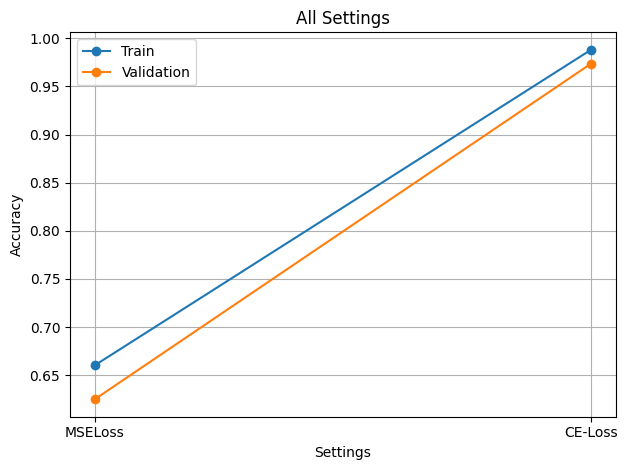

In [ ]:
import matplotlib.pyplot as plt

settings = list(train_accuracies.keys())

# --- Left plot: all settings ---
plt.plot(settings, list(train_accuracies.values()), "o-", label="Train")
plt.plot(settings, list(val_accuracies.values()), "o-", label="Validation")

plt.title("All Settings")
plt.xlabel("Settings")
plt.ylabel("Accuracy")
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

---

### MLP --> Convolutional Neural Network

In [ ]:
import torch
import torch.nn as nn

class ConvNet(nn.Module):
    def __init__(
        self,
        input_channels=1,
        num_classes=10,
        conv1_channels=32,
        conv2_channels=64,
        hidden_dim=128,
    ):
        super().__init__()

        self.net = nn.Sequential(
            nn.Conv2d(input_channels, conv1_channels, kernel_size=3, stride=1),
            nn.ReLU(),
            nn.Conv2d(conv1_channels, conv2_channels, kernel_size=3, stride=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Flatten(),
            nn.Linear(9216, hidden_dim),            # 9216 assumes MNIST-sized inputs (1x28x28)
            nn.ReLU(),
            nn.Linear(hidden_dim, num_classes),
        )

    def forward(self, x):
        return self.net(x)


ConvNet()

ConvNet(
  (net): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU()
    (2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Flatten(start_dim=1, end_dim=-1)
    (6): Linear(in_features=9216, out_features=128, bias=True)
    (7): ReLU()
    (8): Linear(in_features=128, out_features=10, bias=True)
  )
)

In [ ]:
# 3. Classification with Convnet
model = ConvNet()
loss_fn = nn.CrossEntropyLoss()

model, train_losses, val_losses = train(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    loss_fn = loss_fn,
    epochs=epochs,
    lr=1e-3,
    device=device,
)

test_loss = evaluate(model, test_loader, loss_fn, device=device)

print(f"Final Test Loss: {test_loss:.6f}")

Epoch 001 | Train Loss: 0.122665 | Val Loss: 0.054528
Epoch 002 | Train Loss: 0.037429 | Val Loss: 0.048187
Epoch 003 | Train Loss: 0.021776 | Val Loss: 0.038866
Epoch 004 | Train Loss: 0.015920 | Val Loss: 0.041838
Epoch 005 | Train Loss: 0.012804 | Val Loss: 0.045267
Final Test Loss: 0.038044


In [ ]:
train_acc,  train_total,    train_wrong     = accuracy(model, train_loader, pred_fn = lambda out: torch.argmax(out, dim=1))
val_acc,    val_total,      val_wrong       = accuracy(model, val_loader,  pred_fn = lambda out: torch.argmax(out, dim=1))

train_accuracies['CNN'] = train_acc
val_accuracies['CNN']   = val_acc

print(
    f"Train acc={train_acc:.3f}, miss={train_wrong}/{train_total} | "
    f"Val acc={val_acc:.3f}, miss={val_wrong}/{val_total}"
)

Train acc=0.997, miss=152/55000 | Val acc=0.987, miss=64/5000


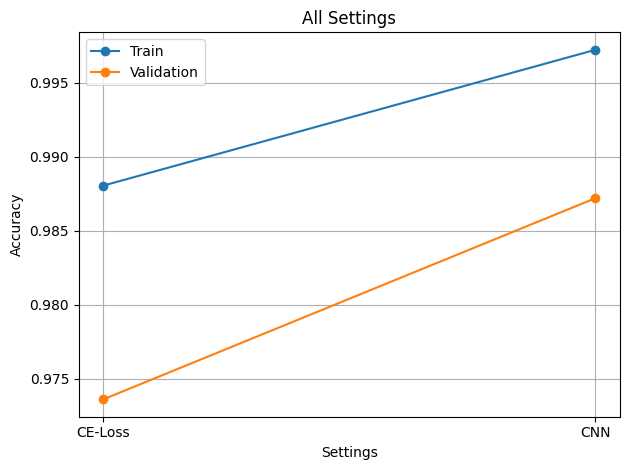

In [ ]:
import matplotlib.pyplot as plt

settings = list(train_accuracies.keys())

# --- Left plot: all settings ---
plt.plot(settings[1:], list(train_accuracies.values())[1:], "o-", label="Train")
plt.plot(settings[1:], list(val_accuracies.values())[1:], "o-", label="Validation")

plt.title("All Settings")
plt.xlabel("Settings")
plt.ylabel("Accuracy")
plt.grid(True)
plt.legend()


plt.tight_layout()
plt.show()

---
### + Dropout

In [ ]:
import torch
import torch.nn as nn

class ConvNetDropout(nn.Module):
    def __init__(
        self,
        input_channels=1,
        num_classes=10,
        conv1_channels=32,
        conv2_channels=64,
        hidden_dim=128,
        dropout1_p=0.25,
        dropout2_p=0.5,
    ):
        super().__init__()

        self.net = nn.Sequential(
            nn.Conv2d(input_channels, conv1_channels, kernel_size=3, stride=1),
            nn.ReLU(),
            nn.Conv2d(conv1_channels, conv2_channels, kernel_size=3, stride=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout(dropout1_p),
            nn.Flatten(),
            nn.Linear(9216, hidden_dim),            # 9216 assumes MNIST-sized inputs (1x28x28)
            nn.ReLU(),
            nn.Dropout(dropout2_p),
            nn.Linear(hidden_dim, num_classes),
        )

    def forward(self, x):
        x = self.net(x)
        return x #torch.nn.functional.log_softmax(x, dim=1)


ConvNetDropout()

ConvNetDropout(
  (net): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU()
    (2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Dropout(p=0.25, inplace=False)
    (6): Flatten(start_dim=1, end_dim=-1)
    (7): Linear(in_features=9216, out_features=128, bias=True)
    (8): ReLU()
    (9): Dropout(p=0.5, inplace=False)
    (10): Linear(in_features=128, out_features=10, bias=True)
  )
)

In [ ]:
# 3. Classification with Convnet
model = ConvNetDropout()
loss_fn = nn.CrossEntropyLoss()

model, train_losses, val_losses = train(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    loss_fn = loss_fn,
    epochs=epochs,
    lr=1e-3,
    device=device,
)

test_loss = evaluate(model, test_loader, loss_fn, device=device)

print(f"Final Test Loss: {test_loss:.6f}")

Epoch 001 | Train Loss: 0.208125 | Val Loss: 0.060821
Epoch 002 | Train Loss: 0.086204 | Val Loss: 0.054128
Epoch 003 | Train Loss: 0.069038 | Val Loss: 0.041357
Epoch 004 | Train Loss: 0.052625 | Val Loss: 0.040873
Epoch 005 | Train Loss: 0.047942 | Val Loss: 0.039436
Final Test Loss: 0.032272


In [ ]:
train_acc,  train_total,    train_wrong     = accuracy(model, train_loader, pred_fn = lambda out: torch.argmax(out, dim=1))
val_acc,    val_total,      val_wrong       = accuracy(model, val_loader,  pred_fn = lambda out: torch.argmax(out, dim=1))

train_accuracies['dropout'] = train_acc
val_accuracies['dropout']   = val_acc

print(
    f"Train acc={train_acc:.3f}, miss={train_wrong}/{train_total} | "
    f"Val acc={val_acc:.3f}, miss={val_wrong}/{val_total}"
)


Train acc=0.996, miss=224/55000 | Val acc=0.989, miss=57/5000


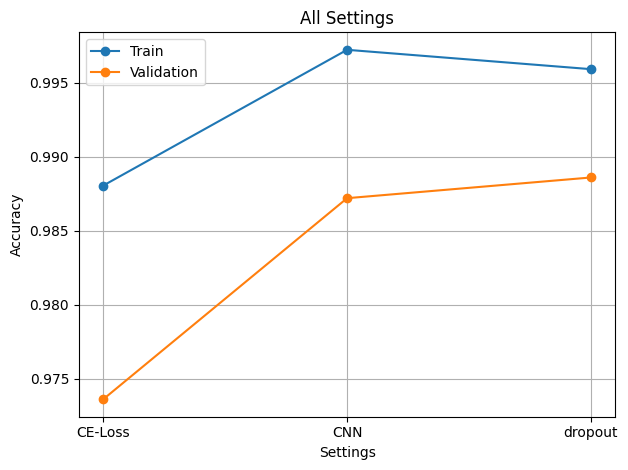

In [ ]:
import matplotlib.pyplot as plt

settings = list(train_accuracies.keys())


# --- Left plot: all settings ---
plt.plot(settings[1:], list(train_accuracies.values())[1:], "o-", label="Train")
plt.plot(settings[1:], list(val_accuracies.values())[1:], "o-", label="Validation")

plt.title("All Settings")
plt.xlabel("Settings")
plt.ylabel("Accuracy")
plt.grid(True)
plt.legend()


plt.tight_layout()
plt.show()


---

#### + Augmentation

In [ ]:
augmentation_transform = transforms.Compose(
    [
        transforms.RandomAffine(
            degrees=10,
            translate=(0.1, 0.1),
            scale=(0.9, 1.1),
            shear=5,
        ),
        transforms.RandomPerspective(
            distortion_scale=0.2,
            p=0.3,
        ),
    ]
    + transform.transforms
)

In [ ]:
from torch.utils.data import Subset

train_data_augm  = datasets.MNIST('./data', train=True, download=True, transform=augmentation_transform)
train_data_augm = Subset(train_data_augm, train_data.indices)

train_loader_augm = DataLoader(train_data_augm, batch_size=64, shuffle=True)

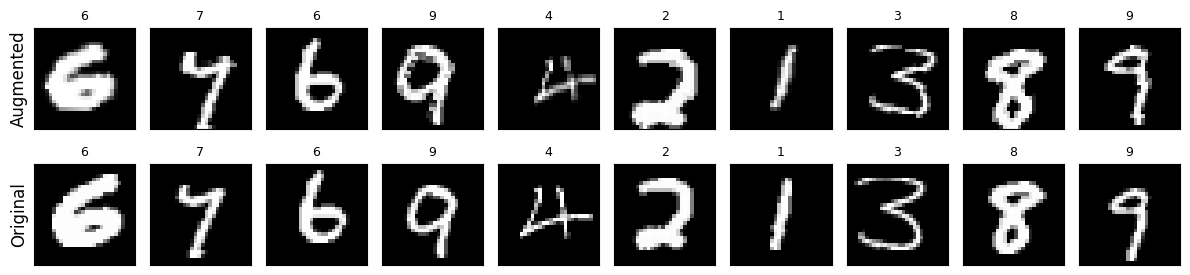

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 10, figsize=(12, 3))

for i in range(10):

    image_augm, label_augm = train_data_augm[i]
    image_orig, label_orig = train_data[i]

    # undo normalization
    image_augm = image_augm * 0.3081 + 0.1307
    image_orig = image_orig * 0.3081 + 0.1307

    # augmented row
    axes[0, i].imshow(image_augm.squeeze(), cmap='gray')
    axes[0, i].set_title(f"{label_augm}", fontsize=9)
    axes[0, i].set_xticks([])
    axes[0, i].set_yticks([])

    # original row
    axes[1, i].imshow(image_orig.squeeze(), cmap='gray')
    axes[1, i].set_title(f"{label_orig}", fontsize=9)
    axes[1, i].set_xticks([])
    axes[1, i].set_yticks([])

axes[0, 0].set_ylabel("Augmented", fontsize=12)
axes[1, 0].set_ylabel("Original", fontsize=12)

plt.tight_layout()
plt.show()

In [ ]:
# Classification with Convnet
model = ConvNetDropout()
loss_fn = nn.CrossEntropyLoss()

model, train_losses, val_losses = train(
    model=model,
    train_loader=train_loader_augm,
    val_loader=val_loader,
    loss_fn = loss_fn,
    epochs=epochs,
    lr=1e-3,
    device=device,
)

test_loss = evaluate(model, test_loader, loss_fn, device=device)

print(f"Final Test Loss: {test_loss:.6f}")

Epoch 001 | Train Loss: 0.506180 | Val Loss: 0.072615
Epoch 002 | Train Loss: 0.244963 | Val Loss: 0.054966
Epoch 003 | Train Loss: 0.188183 | Val Loss: 0.048458
Epoch 004 | Train Loss: 0.167226 | Val Loss: 0.039236
Epoch 005 | Train Loss: 0.151864 | Val Loss: 0.039997
Final Test Loss: 0.024888


In [ ]:
train_acc,  train_total,    train_wrong     = accuracy(model, train_loader, pred_fn = lambda out: torch.argmax(out, dim=1))
val_acc,    val_total,      val_wrong       = accuracy(model, val_loader,  pred_fn = lambda out: torch.argmax(out, dim=1))

train_accuracies['augm'] = train_acc
val_accuracies['augm']   = val_acc

print(
    f"Train acc={train_acc:.3f}, miss={train_wrong}/{train_total} | "
    f"Val acc={val_acc:.3f}, miss={val_wrong}/{val_total}"
)

Train acc=0.990, miss=534/55000 | Val acc=0.988, miss=62/5000


---

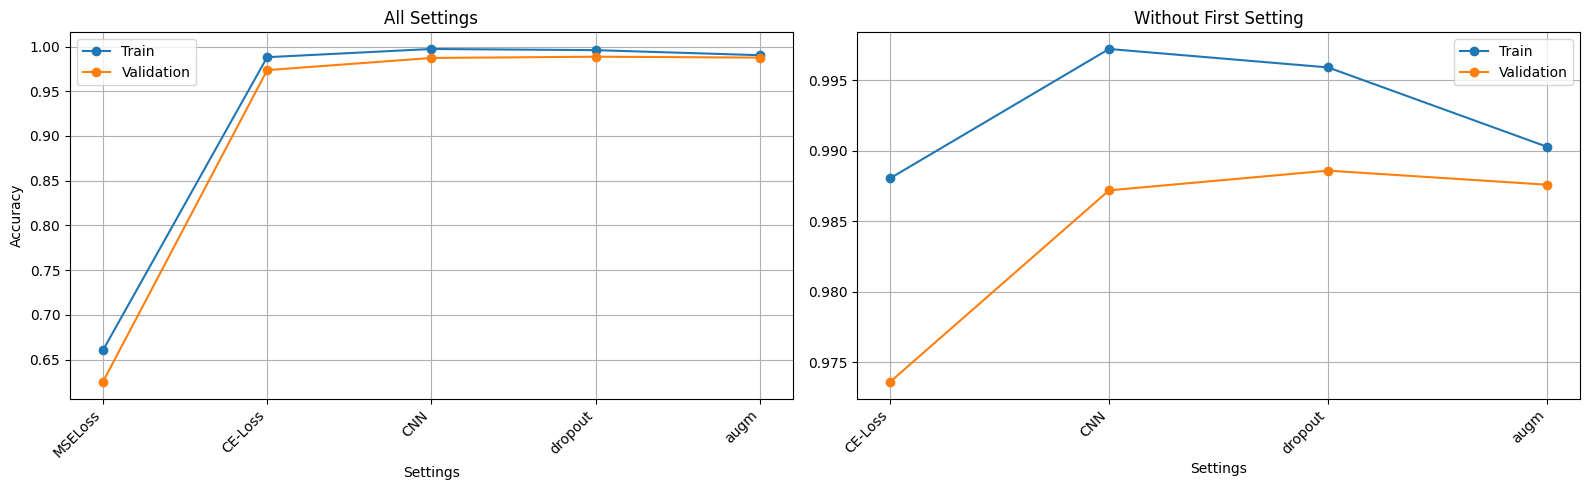

In [ ]:
import matplotlib.pyplot as plt

settings = list(train_accuracies.keys())

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# --- Left plot: all settings ---
axes[0].plot(settings, list(train_accuracies.values()), "o-", label="Train")
axes[0].plot(settings, list(val_accuracies.values()), "o-", label="Validation")
#axes[0].plot(settings, list(test_accuracies.values()), "o-", label="Test")

axes[0].set_title("All Settings")
axes[0].set_xlabel("Settings")
axes[0].set_ylabel("Accuracy")
axes[0].grid(True)
axes[0].legend()

for tick in axes[0].get_xticklabels():
    tick.set_rotation(45)
    tick.set_ha("right")

# --- Right plot: excluding first setting ---
axes[1].plot(settings[1:], list(train_accuracies.values())[1:], "o-", label="Train")
axes[1].plot(settings[1:], list(val_accuracies.values())[1:], "o-", label="Validation")

axes[1].set_title("Without First Setting")
axes[1].set_xlabel("Settings")
axes[1].grid(True)
axes[1].legend()

for tick in axes[1].get_xticklabels():
    tick.set_rotation(45)
    tick.set_ha("right")

plt.tight_layout()
plt.show()